# Pre-Release Sales Prediction for Steam Games
## Notebook 2 of 3 — Exploratory Analysis

This notebook examines the modeling table produced in Notebook 1 before any model is fitted. It
has three purposes:
1. describe the indicators and the target (the equivalent of Table I in the parent paper),
2. confirm the data issues that motivated the target definition and the validation design, and
3. check that the pre-release indicators carry a measurable relationship with sales, so that the
   modeling stage has signal to learn from.

In [1]:
import json
import os

import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import numpy as np
import pandas as pd

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 40)
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3, "font.size": 10,
})
BLUE, GREEN, RED, GREY = "#4C72B0", "#55A868", "#C44E52", "#8C8C8C"

FIG_DIR = os.path.join("..", "outputs", "figures")
TAB_DIR = os.path.join("..", "outputs", "tables")
DATA_DIR = os.path.join("..", "data", "processed")

data = pd.read_csv(os.path.join(DATA_DIR, "steam_model_table.csv.gz"), parse_dates=["release_dt"])
with open(os.path.join(DATA_DIR, "feature_spec.json")) as f:
    spec = json.load(f)
GROUPS = spec["groups"]
base_rate = data["is_hit"].mean()
print(f"{len(data):,} games released {data['release_dt'].min().date()} to {data['release_dt'].max().date()} | "
      f"{sum(len(c) for c in GROUPS.values())} indicators in {len(GROUPS)} groups | hit rate {base_rate:.1%}")

76,074 games released 2010-01-08 to 2024-06-30 | 62 indicators in 15 groups | hit rate 10.3%


---
# 4. Analysis

## 4.1 Descriptive statistics

Table 1 follows the format of the parent paper's feature statistics table (mean, mode, median,
minimum, maximum, missing values). Indicators are shown in their natural units; the log-transformed
versions used for modeling are monotone transformations of these.

In [2]:
table1_cols = {
    "price": "List price (USD)",
    "n_languages": "Supported languages",
    "n_screenshots": "Screenshots",
    "lead_days": "Store-page lead time (days)",
    "dev_prior_releases": "Developer prior releases",
    "same_week_releases": "Same-week releases",
    "required_age": "Required age",
    "metacritic_score": "Metacritic score",
    "owners_mid": "Estimated owners (target)",
}
rows = []
for col, label in table1_cols.items():
    s = data[col]
    rows.append({
        "Indicator": label, "Mean": s.mean(), "Mode": s.mode().iloc[0], "Median": s.median(),
        "Min": s.min(), "Max": s.max(), "Missing": f"{s.isna().sum():,} ({s.isna().mean():.0%})",
    })
table1 = pd.DataFrame(rows).set_index("Indicator")
table1.to_csv(os.path.join(TAB_DIR, "table1_descriptive_statistics.csv"))
table1.style.format({"Mean": "{:,.2f}", "Mode": "{:,.0f}", "Median": "{:,.0f}", "Min": "{:,.0f}", "Max": "{:,.0f}"}) \
    .set_caption("Table 1. Descriptive statistics of key indicators")

,Mean,Mode,Median,Min,Max,Missing
Indicator,,,,,,
List price (USD),8.05,5,5,0,"1,000",0 (0%)
Supported languages,4.49,1,1,0,103,0 (0%)
Screenshots,9.02,5,7,0,183,0 (0%)
Store-page lead time (days),198.02,0,56,0,"5,739",292 (0%)
Developer prior releases,3.28,0,0,0,159,0 (0%)
Same-week releases,186.21,250,181,1,413,0 (0%)
Required age,0.22,0,0,0,21,0 (0%)
Metacritic score,73.23,80,75,20,97,"72,456 (95%)"
Estimated owners (target),"117,622.25","10,000","10,000","10,000","150,000,000",0 (0%)


**Observations.**
- All indicators are fully populated except two. Store-page lead time is missing for 0.4% of games,
  where the release date predates the estimated page creation (re-releases; Notebook 1, Section
  3.2). Metacritic score is missing for 95% of games, which is why it is limited to a side analysis.
- Price, languages, lead time, developer prior releases and the target are strongly right-skewed:
  the median game is priced at $4.99, supports one language and is a developer's first release,
  while the means are pulled up by a minority of large productions. This supports the log
  transformations applied in Notebook 1.
- Launch competition is roughly symmetric (mean 186, median 181 same-week releases).

## 4.2 Distribution of the target

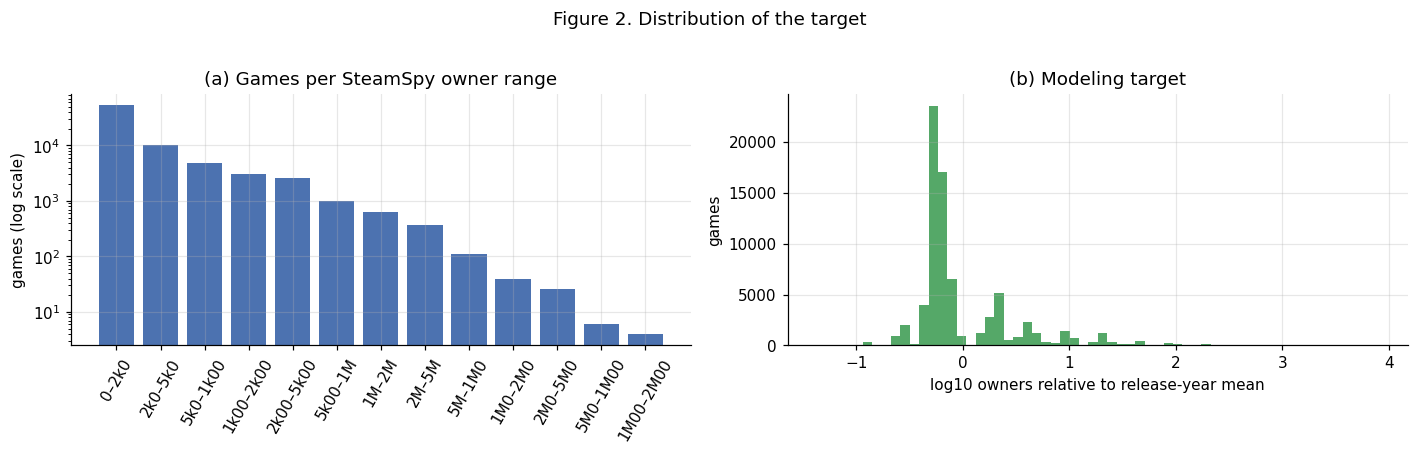

Share in lowest range (<20k owners): 70.1%
Share with >= 1M owners: 1.56%


In [3]:
order = data.drop_duplicates("estimated_owners").sort_values("owners_low")["estimated_owners"].tolist()
counts = data["estimated_owners"].value_counts().reindex(order)
labels = [o.replace("000000", "M").replace("000", "k").replace(" - ", "–") for o in order]

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].bar(labels, counts.values, color=BLUE)
axes[0].set_yscale("log")
axes[0].set_ylabel("games (log scale)")
axes[0].set_title("(a) Games per SteamSpy owner range")
axes[0].tick_params(axis="x", rotation=60)
axes[1].hist(data["rel_log_owners"], bins=60, color=GREEN)
axes[1].set_xlabel("log10 owners relative to release-year mean")
axes[1].set_ylabel("games")
axes[1].set_title("(b) Modeling target")
fig.suptitle("Figure 2. Distribution of the target", y=1.02)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "fig02_target_distribution.png"), dpi=150, bbox_inches="tight")
plt.show()

share = counts / counts.sum()
print(f"Share in lowest range (<20k owners): {share.iloc[0]:.1%}")
print(f"Share with >= 1M owners: {share[data.drop_duplicates('estimated_owners').set_index('estimated_owners').loc[order, 'owners_low'].values >= 1e6].sum():.2%}")

**Observations.** Sales are extremely concentrated: about 70% of games fall in the lowest owner range
(fewer than 20,000 owners), while fewer than 2% exceed one million owners. On a linear scale these few games would
dominate squared-error metrics, confirming the need for a logarithmic target. The target is also
**discrete** — every game in a range receives the same midpoint — which places a ceiling on the R²
any model can achieve against it.

## 4.3 Temporal structure

This section tests the two time effects described in Notebook 1, Section 3.1: shorter time on sale
for recent games, and growth in the number of competing releases.

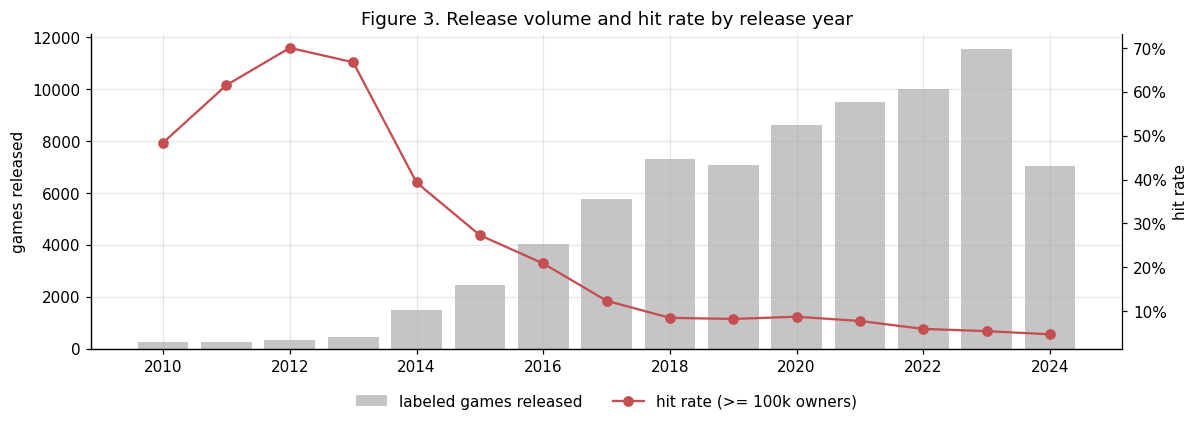

year,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
games,254.000,260.000,317.000,436.000,1485.000,2454.000,4024.000,5747.000,7305.000,7082.000,8615.000,9497.000,10010.000,11564.000,7024.000
mean_log_owners,5.049,5.286,5.381,5.360,4.900,4.667,4.534,4.351,4.262,4.238,4.262,4.246,4.207,4.173,4.139
hit_rate,0.484,0.615,0.700,0.667,0.393,0.273,0.208,0.124,0.084,0.082,0.087,0.077,0.059,0.054,0.047


In [4]:
by_year = data.groupby("year").agg(games=("appid", "size"), mean_log_owners=("log_owners", "mean"),
                                   hit_rate=("is_hit", "mean"))

fig, ax1 = plt.subplots(figsize=(11, 4))
ax1.bar(by_year.index, by_year["games"], color=GREY, alpha=0.5, label="labeled games released")
ax1.set_ylabel("games released")
ax2 = ax1.twinx()
ax2.plot(by_year.index, by_year["hit_rate"], color=RED, marker="o", label="hit rate (>= 100k owners)")
ax2.set_ylabel("hit rate")
ax2.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
ax2.grid(False)
ax2.spines["right"].set_visible(True)
lines = ax1.get_legend_handles_labels()[0] + ax2.get_legend_handles_labels()[0]
ax1.legend(lines, [l.get_label() for l in lines], loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=2, frameon=False)
ax1.set_title("Figure 3. Release volume and hit rate by release year")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "fig03_release_volume_and_hit_rate.png"), dpi=150, bbox_inches="tight")
plt.show()
by_year.round(3).T

**Observations.** Labeled releases grow from about 250 per year in 2010–2012 to more than 10,000 per
year from 2022, while the share of games reaching 100,000 owners falls from 48–70% in 2010–2013 to
about 5% in 2023–2024. The early cohorts are small and consist largely of established titles, and
recent games have had less time on sale; the decline therefore reflects market saturation and
exposure time rather than the games' own characteristics. Two design consequences follow:

1. **Cohort-relative target.** Measuring each game against its own release year removes this
   downward drift, so the model learns what distinguishes successful games rather than when they
   were released.
2. **Chronological validation.** A model will in practice be trained on past releases and applied
   to future ones. The final test in Notebook 3 therefore uses the most recent releases as a
   hold-out set, in addition to cross-validation.

## 4.4 Relationship between key indicators and sales

Hit rate (share of games with at least 100,000 owners) across bands of each continuous indicator.
The dashed line marks the overall hit rate.

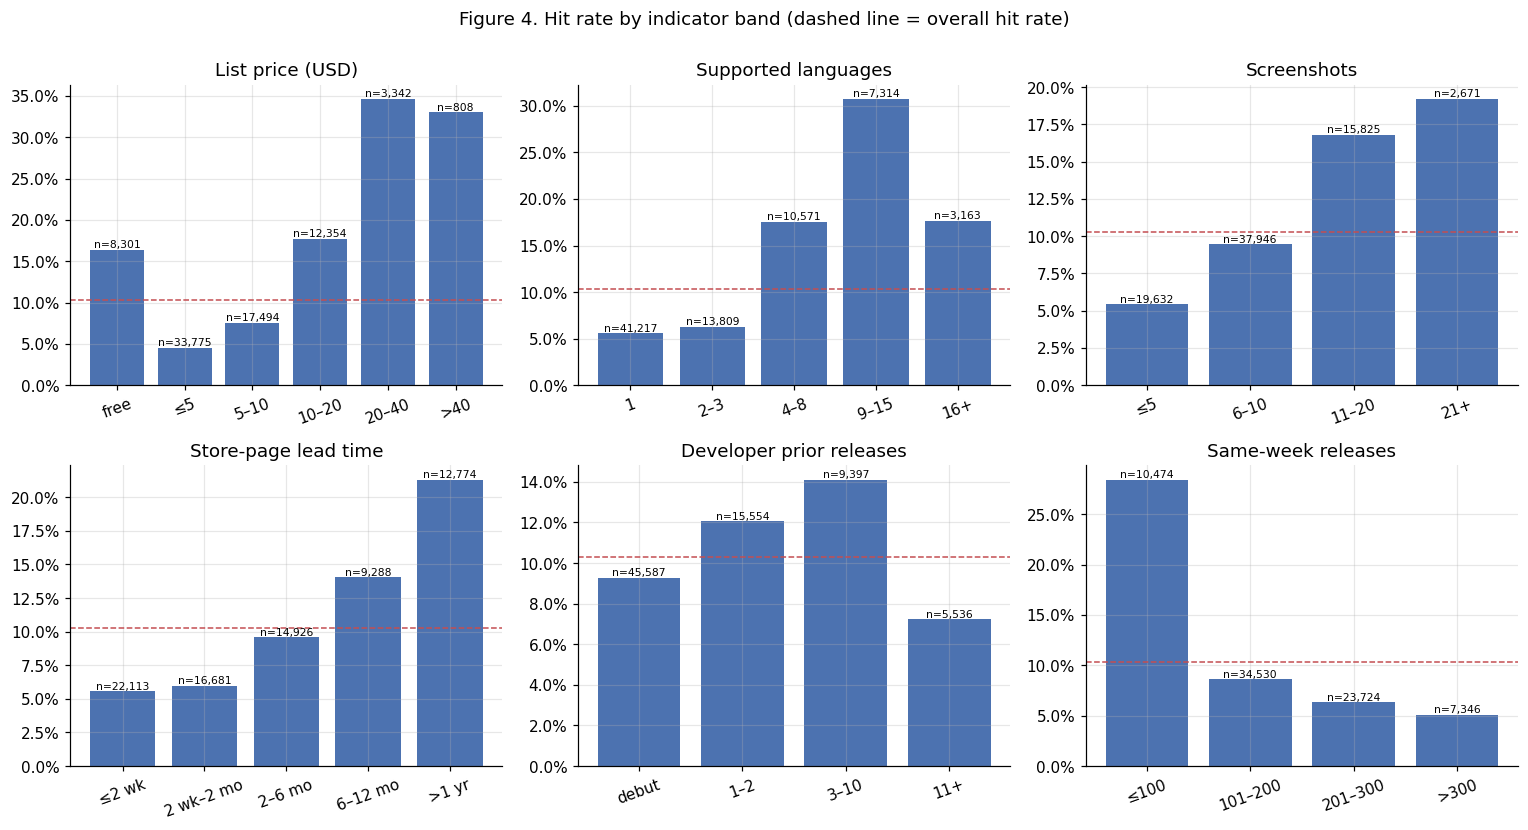

In [5]:
BANDS = [
    ("price", "List price (USD)", [-0.01, 0, 5, 10, 20, 40, 1000], ["free", "≤5", "5–10", "10–20", "20–40", ">40"]),
    ("n_languages", "Supported languages", [0, 1, 3, 8, 15, 200], ["1", "2–3", "4–8", "9–15", "16+"]),
    ("n_screenshots", "Screenshots", [-1, 5, 10, 20, 500], ["≤5", "6–10", "11–20", "21+"]),
    ("lead_days", "Store-page lead time", [-1, 14, 60, 180, 365, 10_000], ["≤2 wk", "2 wk–2 mo", "2–6 mo", "6–12 mo", ">1 yr"]),
    ("dev_prior_releases", "Developer prior releases", [-1, 0, 2, 10, 10_000], ["debut", "1–2", "3–10", "11+"]),
    ("same_week_releases", "Same-week releases", [0, 100, 200, 300, 10_000], ["≤100", "101–200", "201–300", ">300"]),
]
fig, axes = plt.subplots(2, 3, figsize=(14, 7.5))
band_tables = {}
for ax, (col, title, bins, lab) in zip(axes.ravel(), BANDS):
    band = pd.cut(data[col], bins=bins, labels=lab, include_lowest=True)
    t = data.groupby(band, observed=True)["is_hit"].agg(hit_rate="mean", games="size")
    band_tables[title] = t
    ax.bar(t.index.astype(str), t["hit_rate"], color=BLUE)
    ax.axhline(base_rate, color=RED, ls="--", lw=1)
    ax.set_title(title)
    ax.yaxis.set_major_formatter(PercentFormatter(1.0))
    for i, (h, n) in enumerate(zip(t["hit_rate"], t["games"])):
        ax.text(i, h, f"n={n:,}", ha="center", va="bottom", fontsize=7)
    ax.tick_params(axis="x", rotation=20)
fig.suptitle("Figure 4. Hit rate by indicator band (dashed line = overall hit rate)", y=1.0)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "fig04_hit_rate_by_indicator.png"), dpi=150, bbox_inches="tight")
plt.show()

**Observations.**
- **Price** has a strong positive association above the entry tier: games priced at $20–40 reach
  100,000 owners in 35% of cases, compared with 5% for games priced at $5 or less. Free games (16%)
  also exceed the base rate, consistent with the lower barrier to acquiring a free title.
- **Localisation** rises from 6% for single-language games to 31% at 9–15 languages, then falls to
  18% at 16 or more. This non-monotone pattern cannot be represented by a single linear
  coefficient, which anticipates an advantage for tree-based models.
- **Screenshots** (5% → 19%) and **store-page lead time** (6% → 21%) both increase steadily, consistent
  with greater investment in presentation and a longer marketing period.
- **Developer experience** peaks for studios with 3–10 prior releases (14%) and drops for very
  prolific developers (7%), whose catalogues are dominated by many small releases.
- **Launch competition** shows a strong negative association (28% in weeks with at most 100 releases,
  5% in weeks with more than 300), but this is largely confounded with release year: quiet weeks
  occur mainly in the early 2010s, when hit rates were high. Its independent contribution is
  assessed with the cohort-relative target in Notebook 3.

## 4.5 Genres and design categories

Hit rate among games carrying each flag, relative to the overall hit rate (lift). A lift of 2.0
means games with that flag reach 100,000 owners twice as often as the average game.

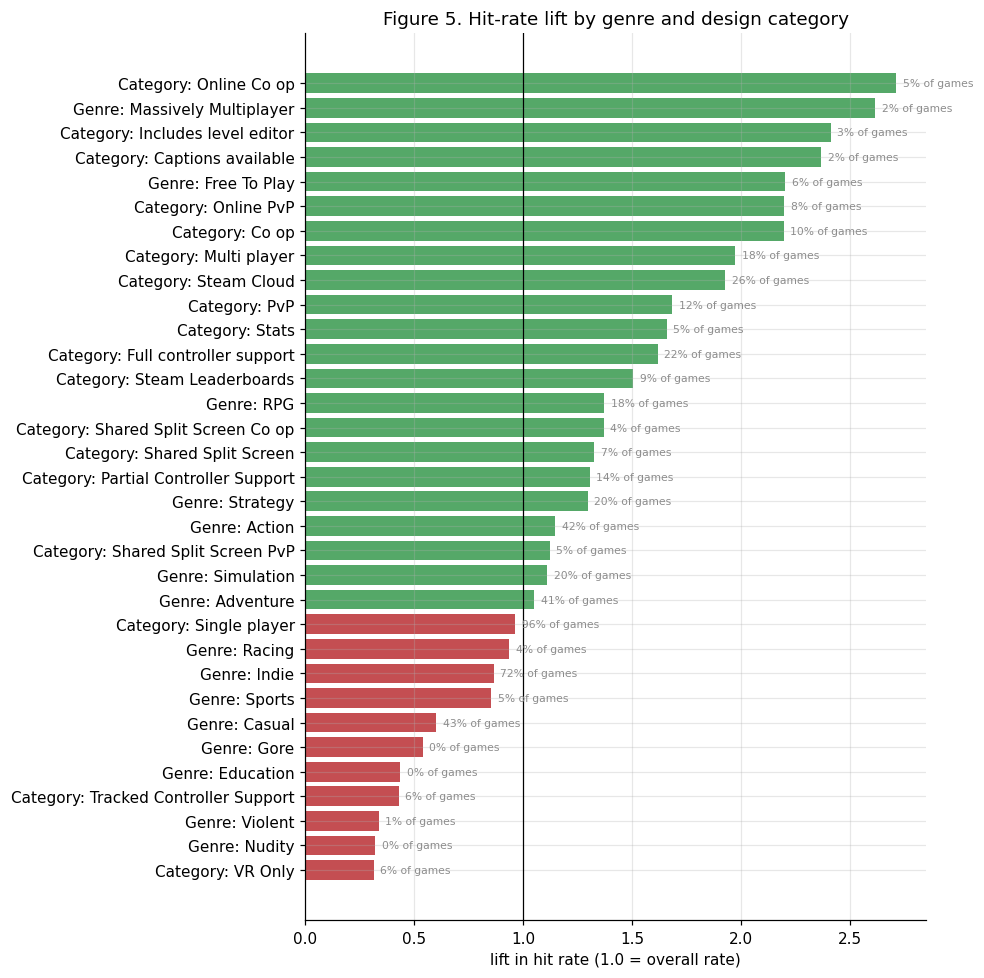

In [6]:
flag_cols = GROUPS["Genres"] + GROUPS["Design categories"]
lift = pd.DataFrame({
    "prevalence": [data[c].mean() for c in flag_cols],
    "hit_rate": [data.loc[data[c] == 1, "is_hit"].mean() for c in flag_cols],
}, index=[c.replace("genre_", "Genre: ").replace("cat_", "Category: ").replace("_", " ") for c in flag_cols])
lift["lift"] = lift["hit_rate"] / base_rate
lift = lift.sort_values("lift")

fig, ax = plt.subplots(figsize=(9, 9))
ax.barh(lift.index, lift["lift"], color=np.where(lift["lift"] >= 1, GREEN, RED))
ax.axvline(1, color="black", lw=0.8)
for i, (l, p) in enumerate(zip(lift["lift"], lift["prevalence"])):
    ax.text(l + 0.03, i, f"{p:.0%} of games", va="center", fontsize=7, color=GREY)
ax.set_xlabel("lift in hit rate (1.0 = overall rate)")
ax.set_title("Figure 5. Hit-rate lift by genre and design category")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "fig05_genre_category_lift.png"), dpi=150)
plt.show()

**Observations.** Multiplayer-oriented design is associated with the highest hit rates (online co-op
2.7×, massively multiplayer 2.6×, online PvP and co-op about 2.2×), together with free-to-play
(2.2×) and full controller support (1.6×). The most common flags (Indie, Casual, Single-player) sit
at or below the base rate because they describe the bulk of small releases. VR-only games reach
100,000 owners at about one third of the average rate, reflecting the small VR install base.
Several flags cover only a small share of games, so their individual effects are estimated with
less precision.

## 4.6 Correlation among indicators

Strongly correlated predictors make Linear Regression coefficients unstable and hard to interpret,
although they do not reduce predictive accuracy. Spearman rank correlation is used because most
indicators are skewed or ordinal.

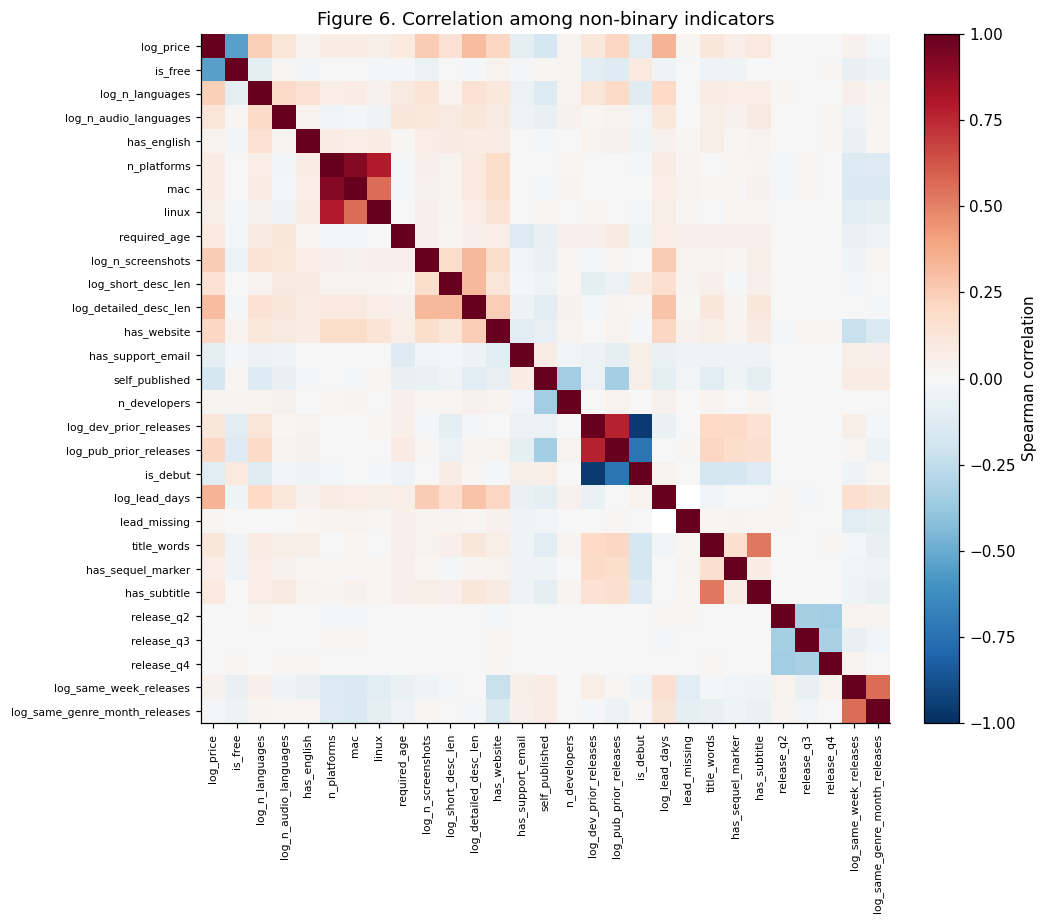

spearman
log_dev_prior_releases is_debut               -0.960026
n_platforms            mac                     0.915576
                       linux                   0.795066
log_dev_prior_releases log_pub_prior_releases  0.769947
log_pub_prior_releases is_debut               -0.726576

In [7]:
numeric = [c for g, cols in GROUPS.items() if g not in ("Genres", "Design categories") for c in cols]
corr = data[numeric].corr(method="spearman")

fig, ax = plt.subplots(figsize=(10, 8.5))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(numeric)))
ax.set_xticklabels(numeric, rotation=90, fontsize=7)
ax.set_yticks(range(len(numeric)))
ax.set_yticklabels(numeric, fontsize=7)
ax.grid(False)
plt.colorbar(im, fraction=0.046, pad=0.04, label="Spearman correlation")
ax.set_title("Figure 6. Correlation among non-binary indicators")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "fig06_indicator_correlation.png"), dpi=150)
plt.show()

pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
strong = pairs[pairs.abs() >= 0.6].sort_values(key=abs, ascending=False)
strong.rename("spearman").to_frame()

**Observations.** All pairs with |ρ| ≥ 0.6 are structural: the debut flag is defined from the
developer's prior releases (ρ = −0.96), the platform count is the sum of the Mac and Linux flags,
and developer and publisher prior releases coincide for self-published games. No pair of
conceptually distinct indicators is strongly correlated. For Linear Regression, coefficients within
these structural pairs should be interpreted jointly rather than individually.

## Summary of Notebook 2

- The target is highly skewed and discrete; the log scale and the cohort-relative definition are
  both necessary.
- Hit rates fall steadily over time for reasons external to the games, supporting the
  cohort-relative target and a chronological hold-out test.
- Price, localisation, screenshots, store-page lead time and multiplayer design all show clear
  relationships with sales. Several of these relationships are non-linear (localisation,
  developer experience), which suggests tree-based models may outperform Linear Regression.
- Collinearity is limited to structurally related indicators.